In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset,DataLoader
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,balanced_accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix
print(torch.__version__)

2.11.0+cu128


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [3]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)

PyTorch: 2.11.0+cu128
CUDA available: True
CUDA version: 12.8


In [4]:
!nvidia-smi

Mon Nov 16 15:19:09 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 591.66                 Driver Version: 591.66         CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4050 ...  WDDM  |   00000000:01:00.0  On |                  N/A |
| N/A   41C    P8              2W /   50W |    1005MiB /   6141MiB |     19%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
train_df = pd.read_csv("../data/raw/mitbih_train.csv")
train_df.head()

,9.779411554336547852e-01,9.264705777168273926e-01,6.813725233078002930e-01,2.450980395078659058e-01,1.544117629528045654e-01,1.911764740943908691e-01,1.519607901573181152e-01,8.578431606292724609e-02,5.882352963089942932e-02,4.901960864663124084e-02,...,0.000000000000000000e+00.79,0.000000000000000000e+00.80,0.000000000000000000e+00.81,0.000000000000000000e+00.82,0.000000000000000000e+00.83,0.000000000000000000e+00.84,0.000000000000000000e+00.85,0.000000000000000000e+00.86,0.000000000000000000e+00.87,0.000000000000000000e+00.88
0,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.927461,1.000000,0.626943,0.193437,0.094991,0.072539,0.043178,0.053541,0.093264,0.189983,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
X = train_df.iloc[:,:-1]
y = train_df.iloc[:,-1]

In [7]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("X dtype:", X.dtypes.unique())
print("y dtype:", y.dtype)

X shape: (87553, 187)
y shape: (87553,)
X dtype: [dtype('float64')]
y dtype: float64


In [9]:
indices = np.arange(len(X))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.15,
    random_state=42,
    stratify=y
)

np.save("../data/processed/train_idx.npy", train_idx)
np.save("../data/processed/val_idx.npy", val_idx)

train_X = X.iloc[train_idx]
val_X = X.iloc[val_idx]

train_y = y.iloc[train_idx]
val_y = y.iloc[val_idx]

In [10]:
train_features = train_X
train_labels = train_y

val_features = val_X
val_labels = val_y

In [11]:
train_features = torch.tensor(train_features.to_numpy(), dtype=torch.float32)
train_labels = torch.tensor(train_labels.to_numpy(), dtype=torch.long)

val_features = torch.tensor(val_features.to_numpy(), dtype=torch.float32)
val_labels = torch.tensor(val_labels.to_numpy(), dtype=torch.long)

In [12]:
class ECGDataset(Dataset):
    def __init__(self, features, labels):
        self.features = features
        self.labels = labels

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        signal = self.features[idx]
        label = self.labels[idx]

        return signal, label

In [13]:
train_dataset = ECGDataset(train_features, train_labels)
val_dataset = ECGDataset(val_features, val_labels)

In [14]:
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))

print("Signal shape:", train_dataset[0][0].shape)
print("Label:", train_dataset[0][1])

Training: 74420
Validation: 13133
Signal shape: torch.Size([187])
Label: tensor(0)


In [15]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True,pin_memory=True)
val_loader = DataLoader(val_dataset,batch_size=32,shuffle=True,pin_memory=True)

In [16]:
signals, labels = next(iter(train_loader))

In [17]:
print(signals.shape)
print(labels.shape)

torch.Size([32, 187])
torch.Size([32])


In [18]:
signals = signals.unsqueeze(1)

print(signals.shape)

torch.Size([32, 1, 187])


In [19]:
class ECG_CNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv1d(1, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(128, 5)
        )

    def forward(self, x):
        x = x.unsqueeze(1)
        x = self.features(x)
        x = self.classifier(x)

        return x


In [20]:
model = ECG_CNN().to(device)
print(model)

ECG_CNN(
  (features): Sequential(
    (0): Conv1d(1, 32, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): AdaptiveAvgPool1d(output_size=1)
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=128, out_features=5, bias=True)
  )
)


In [21]:
learning_rate = 0.0001
epochs = 50
patience = 8
patience_counter = 0
best_macro_f1 = 0

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [22]:
history = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "accuracy": [],
    "balanced_accuracy": [],
    "precision": [],
    "recall": [],
    "macro_f1": []
}

In [23]:
for epoch in range(epochs):

    # ---------------- TRAINING ----------------
    model.train()

    total_train_loss = 0
    train_samples = 0

    for features, labels in train_loader:

        features = features.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(features)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_train_loss += loss.item() * features.size(0)
        train_samples += features.size(0)

    avg_train_loss = total_train_loss / train_samples

    # ---------------- VALIDATION ----------------
    model.eval()

    total_val_loss = 0
    val_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for features, labels in val_loader:

            features = features.to(device)
            labels = labels.to(device)

            outputs = model(features)

            loss = criterion(outputs, labels)

            total_val_loss += loss.item() * features.size(0)
            val_samples += features.size(0)

            predictions = torch.argmax(outputs, dim=1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_val_loss = total_val_loss / val_samples

    # ---------------- METRICS ----------------
    accuracy = accuracy_score(all_labels, all_preds)

    balanced_acc = balanced_accuracy_score(
        all_labels, all_preds
    )

    precision = precision_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    recall = recall_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    macro_f1 = f1_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    # ---------------- SAVE HISTORY ----------------
    history["epoch"].append(epoch + 1)
    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["accuracy"].append(accuracy)
    history["balanced_accuracy"].append(balanced_acc)
    history["precision"].append(precision)
    history["recall"].append(recall)
    history["macro_f1"].append(macro_f1)

    # ---------------- EARLY STOPPING ----------------
    if macro_f1 > best_macro_f1:

        best_macro_f1 = macro_f1
        patience_counter = 0

        torch.save(
            model.state_dict(),
            "../models/cnn_plain.pt"
        )

        print("Best model saved!")

    else:

        patience_counter += 1

    # ---------------- EPOCH RESULTS ----------------
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Balanced Acc: {balanced_acc:.4f} | "
        f"Macro F1: {macro_f1:.4f}"
    )

    if patience_counter >= patience:

        print("Early stopping triggered!")
        break

Best model saved!
Epoch [1/50] Train Loss: 0.3450 | Val Loss: 0.2040 | Accuracy: 0.9380 | Balanced Acc: 0.5261 | Macro F1: 0.5523
Best model saved!
Epoch [2/50] Train Loss: 0.1810 | Val Loss: 0.1651 | Accuracy: 0.9562 | Balanced Acc: 0.6497 | Macro F1: 0.6720
Best model saved!
Epoch [3/50] Train Loss: 0.1510 | Val Loss: 0.1320 | Accuracy: 0.9611 | Balanced Acc: 0.6615 | Macro F1: 0.6900
Best model saved!
Epoch [4/50] Train Loss: 0.1342 | Val Loss: 0.1239 | Accuracy: 0.9645 | Balanced Acc: 0.7031 | Macro F1: 0.7647
Best model saved!
Epoch [5/50] Train Loss: 0.1233 | Val Loss: 0.1163 | Accuracy: 0.9658 | Balanced Acc: 0.7116 | Macro F1: 0.7746
Best model saved!
Epoch [6/50] Train Loss: 0.1157 | Val Loss: 0.1056 | Accuracy: 0.9706 | Balanced Acc: 0.7803 | Macro F1: 0.8368
Epoch [7/50] Train Loss: 0.1091 | Val Loss: 0.1009 | Accuracy: 0.9720 | Balanced Acc: 0.7738 | Macro F1: 0.8311
Best model saved!
Epoch [8/50] Train Loss: 0.1039 | Val Loss: 0.0983 | Accuracy: 0.9724 | Balanced Acc: 0.80

In [24]:
history_df = pd.DataFrame(history)

history_df.to_csv(
    "../results/metrics/cnn_plain_history.csv",
    index=False
)

history_df

,epoch,train_loss,val_loss,accuracy,balanced_accuracy,precision,recall,macro_f1
0,1,0.344952,0.203996,0.938019,0.526128,0.736058,0.526128,0.552270
1,2,0.180952,0.165058,0.956217,0.649733,0.718575,0.649733,0.671952
2,3,0.150967,0.132041,0.961090,0.661491,0.931012,0.661491,0.690007
3,4,0.134206,0.123908,0.964517,0.703073,0.946442,0.703073,0.764682
4,5,0.123295,0.116252,0.965811,0.711583,0.943980,0.711583,0.774626
5,6,0.115736,0.105648,0.970608,0.780325,0.931370,0.780325,0.836790
6,7,0.109146,0.100886,0.971979,0.773802,0.944119,0.773802,0.831068
7,8,0.103944,0.098334,0.972360,0.806598,0.941025,0.806598,0.860740
8,9,0.100647,0.100886,0.974796,0.840679,0.918519,0.840679,0.874656
9,10,0.096991,0.099688,0.973806,0.839673,0.909115,0.839673,0.870768


In [25]:
model.load_state_dict(
    torch.load(
        "../models/cnn_plain.pt",
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Best CNN model loaded successfully!")

Best CNN model loaded successfully!


In [26]:
all_preds = []
all_labels = []

with torch.no_grad():

    for features, labels in val_loader:

        features = features.to(device)
        labels = labels.to(device)

        outputs = model(features)

        predictions = torch.argmax(outputs, dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

In [27]:
class_names = [
    "Normal",
    "Supraventricular",
    "Ventricular",
    "Fusion",
    "Unknown"
]

report = classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    "../results/metrics/cnn_plain_classification_report.csv"
)

report_df

,precision,recall,f1-score,support
Normal,0.985963,0.995033,0.990477,10871.000000
Supraventricular,0.895582,0.669670,0.766323,333.000000
Ventricular,0.959207,0.948157,0.953650,868.000000
Fusion,0.853933,0.791667,0.821622,96.000000
Unknown,0.986542,0.987565,0.987053,965.000000
accuracy,0.981649,0.981649,0.981649,0.981649
macro avg,0.936246,0.878418,0.903825,13133.000000
weighted avg,0.980980,0.981649,0.980874,13133.000000


In [28]:
cm = confusion_matrix(all_labels, all_preds)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    "../results/metrics/cnn_plain_confusion_matrix.csv"
)

cm_df

,Normal,Supraventricular,Ventricular,Fusion,Unknown
Normal,10817,23,19,3,9
Supraventricular,102,223,5,2,1
Ventricular,33,1,823,8,3
Fusion,8,2,10,76,0
Unknown,11,0,1,0,953


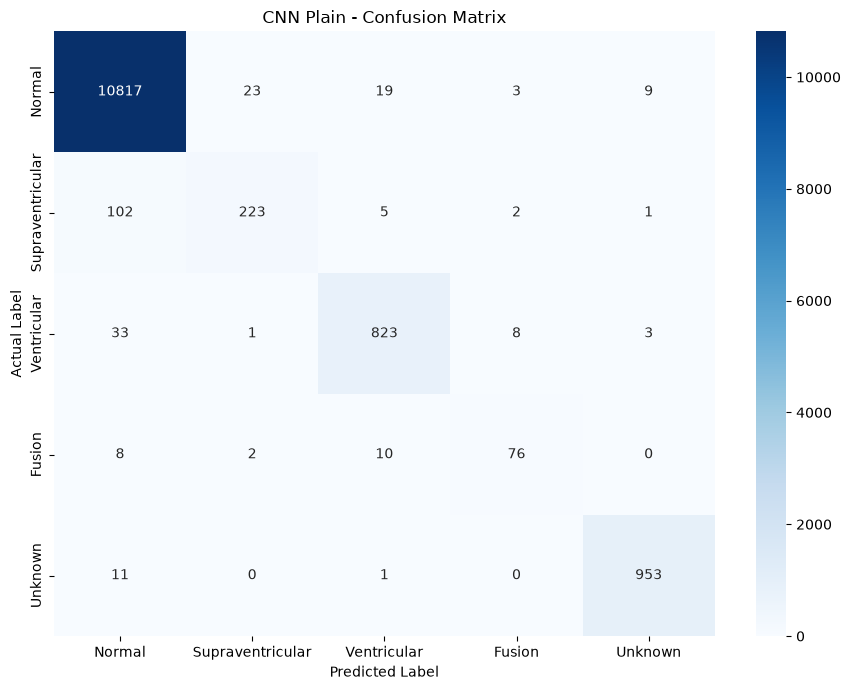

In [29]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("CNN Plain - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "../results/figures/cnn_plain_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

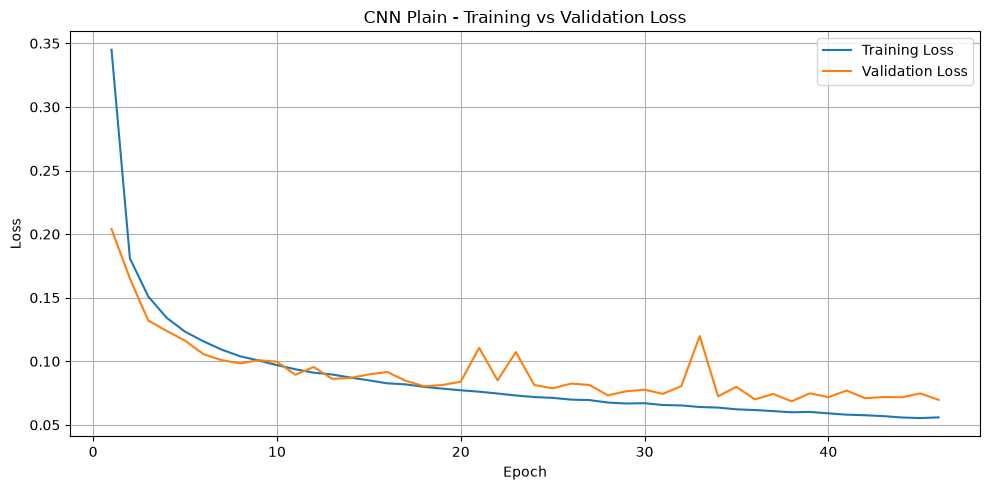

In [30]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Plain - Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/cnn_plain_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

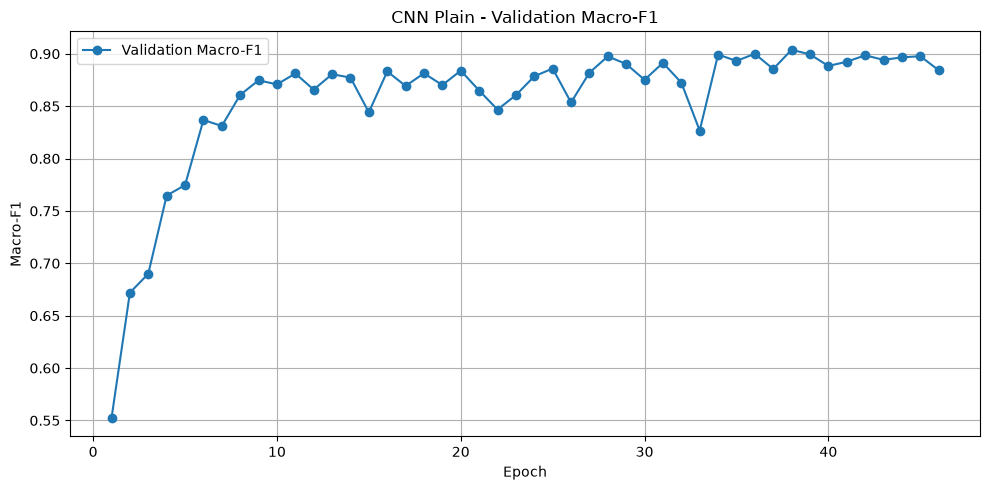

In [31]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("CNN Plain - Validation Macro-F1")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/cnn_plain_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()